<a href="https://colab.research.google.com/github/tustus1022-ui/esaa/blob/main/ESAA_OB_WEEK7_transcription2_book.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<딥러닝 파이토치 교과서> 5장 p.166~179 필사

# **5. 합성곱 신경망 I**
## **5.1 합성곱 신경망**

딥러닝의 역전파는 순전파로 계산된 오차 정보가 신경망의 모든 노드(출력층 → 은닉층 → 입력층)로 전송되는 과정이라 계산이 복잡하고, 많은 자원(CPU/GPU, 메모리)과 시간이 필요함.


이 문제를 해결하려는 것이 **합성곱 신경망**
- 이미지 전체를 한 번에 계산하지 않고 이미지의 **국소적 부분**을 계산함
- 그 결과 시간과 자원을 절약하면서 이미지의 세밀한 부분까지 분석할 수 있음

### **5.1.1 합성곱층의 필요성**

합성곱 신경망은 이미지나 영상 처리에 유용함.

- 기존 방식은 3×3 이미지 배열을 1차원으로 **펼쳐서(flattening)** 각 픽셀에 가중치를 곱한 뒤 은닉층으로 전달함
- 이렇게 펼치면 **데이터의 공간적 구조가 무시됨**
- 이를 방지하려고 도입된 것이 **합성곱층**

### **5.1.2 합성곱 신경망 구조**

합성곱 신경망(CNN, ConvNet)은 음성 인식이나 이미지/영상 인식에 주로 쓰이는 신경망.
다차원 배열 데이터 처리에 특화되어 있어 컬러 이미지 같은 데이터를 다루기 좋음.

**구성 (5개 계층)**

입력층 → 합성곱층 → 풀링층 → 완전연결층 → 출력층

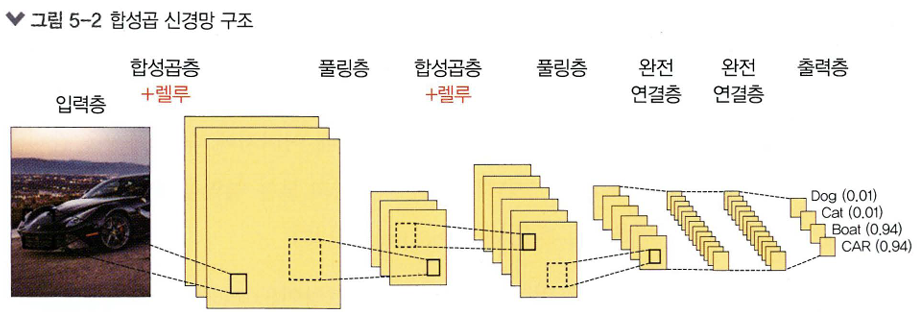

**전체 흐름**

- 합성곱층과 풀링층을 거치면서 입력 이미지의 주요 **특성 벡터(feature vector)**를 추출함
- 추출된 특성 벡터는 완전연결층을 거치며 1차원 벡터로 변환됨
- 출력층에서 **소프트맥스(softmax)** 함수로 최종 결과를 출력함

**입력층 (input layer)**

입력 이미지 데이터가 가장 먼저 거치는 계층.

- 이미지는 1차원이 아니라 **높이(height), 너비(width), 채널(channel)** 값을 갖는 3차원 데이터
- 채널 값은 그레이스케일이면 **1**, 컬러(RGB)면 **3**
- 예: 높이 4, 너비 4, RGB 이미지의 형태(shape)는 (4, 4, 3)

**합성곱층 (convolutional layer)**

입력 데이터에서 **특성을 추출**하는 역할.

- **커널(kernel)/필터**를 사용해 이미지의 특성을 감지함
- 커널이 이미지의 모든 영역을 훑으면서 특성을 추출하고, 그 결과물이 **특성 맵(feature map)**
- 커널 크기는 보통 3×3 또는 5×5
- 커널은 **스트라이드(stride)**, 즉 필터를 적용하는 위치의 간격에 따라 순차적으로 이동함

**합성곱 연산 방법 (그레이스케일)**

- 입력 이미지와 필터를 포개 놓고, 대응되는 숫자끼리 곱한 후 모두 더함 (가중합)
- 필터가 스트라이드만큼 이동하면서 이 연산을 반복해 출력 칸을 하나씩 채움
- 예: (6, 6, 1) 이미지에 3×3 필터를 스트라이드 1로 적용하면 (4, 4, 1) 크기의 특성 맵이 됨
    - 즉, 커널과 스트라이드의 상호 작용으로 특성 맵의 크기가 줄어듦

**컬러 이미지 합성곱**

그레이스케일과 다른 점은 두 가지이고, 스트라이드와 연산 방법은 같음.

1. **필터 채널이 3**
2. RGB 각각에 **서로 다른 가중치**로 합성곱을 적용한 뒤 **결과를 더함**

주의: 필터 채널이 3이어도 **필터 개수는 1개**임.
- 예: 입력 3×3×3, 필터 2×2×3 → 채널별 합성곱 결과 3개를 더해서 2×2 특성 맵 1개가 나옴
- 입력 채널 수와 필터 채널 수는 같아야 함

**필터가 2개 이상인 합성곱**
- 필터 각각이 특성 추출 결과의 **채널 하나**가 됨-
예: 3×3×3 컬러 이미지에 2×2×3 필터 4개를 적용하면 결과는 2×2×4
- 각 필터의 계산 방법은 앞과 동일함

**합성곱층 요약**
- 입력 데이터: W₁ × H₁ × D₁ (W₁: 가로, H₁: 세로, D₁: 채널 또는 깊이)
- 하이퍼파라미터: 필터 개수 K, 필터 크기 F, 스트라이드 S, 패딩 P
- 출력 데이터:
    - W₂ = (W₁ − F + 2P) / S + 1
    - H₂ = (H₁ − F + 2P) / S + 1
    - D₂ = K (출력 채널 수 = 필터 개수)
- 확인 예: (6 − 3 + 0) / 1 + 1 = 4 → 앞 예시의 4×4 특성 맵과 일치

**풀링층 (pooling layer)**

특성 맵의 차원을 **다운 샘플링**해서 연산량을 줄이고, 주요 특성 벡터를 추출해 학습을 효과적으로 만드는 계층.
- **다운 샘플링(sub-sampling)**: 이미지를 축소하는 것

**풀링 연산 2가지**
- **최대 풀링(max pooling)**: 대상 영역에서 최댓값을 추출
- **평균 풀링(average pooling)**: 대상 영역에서 평균을 반환

대부분의 CNN은 **최대 풀링**을 사용함.

평균 풀링은 값을 평균화하기 때문에, 중요한 가중치를 갖는 값의 특성이 희미해질 수 있음.

**풀링 예시 (4×4 입력, 2×2 영역, 스트라이드 2)**
- 최대 풀링: 각 영역에서 최댓값(3, 12, 3, 4)을 선택 → 출력 [[3, 12], [3, 4]]
- 평균 풀링: 각 영역의 평균을 계산 → 출력 [[0, 3], [0, 1]]
    - 예: (3 + (−1) + (−3) + 1) / 4 = 0

**풀링층 요약**

최대 풀링과 평균 풀링은 계산 과정만 다르고 사용하는 파라미터는 같음.
- 입력 데이터: W₁ × H₁ × D₁
- 하이퍼파라미터: 필터 크기 F, 스트라이드 S (패딩과 필터 개수는 없음)
- 출력 데이터:
    - W₂ = (W₁ − F) / S + 1
    - H₂ = (H₁ − F) / S + 1
    - D₂ = D₁ (채널 수는 그대로 유지)
- 확인 예: (4 − 2) / 2 + 1 = 2 → 2×2 출력

**완전연결층 (fully connected layer)**

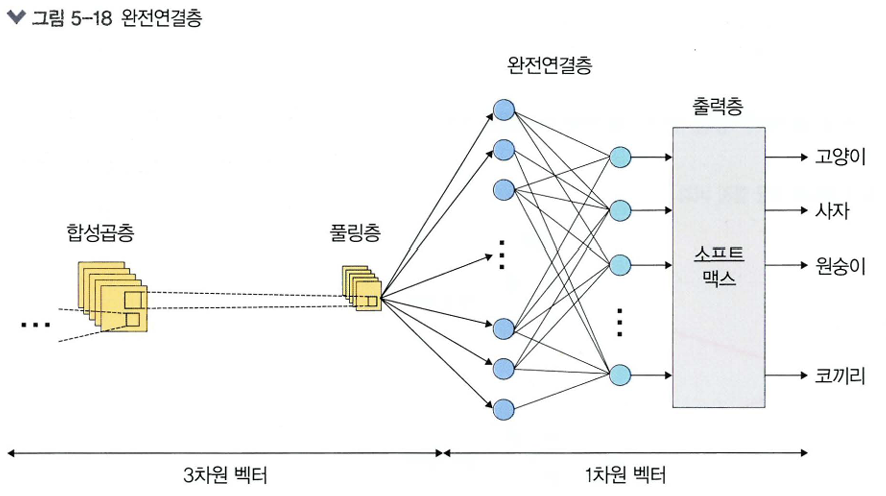


합성곱층과 풀링층을 거치며 차원이 축소된 특성 맵이 최종적으로 전달되는 계층.
- 이 과정에서 이미지가 **3차원 벡터에서 1차원 벡터로 펼쳐짐(flatten)**

**출력층 (output layer)**
- **소프트맥스 활성화 함수**를 사용해 입력받은 값을 0~1 사이 값으로 출력함
- 이미지가 각 레이블(label)에 속할 확률 값이 나옴
- **가장 높은 확률 값을 갖는 레이블**이 최종 값으로 선정됨

### **5.1.3 1D, 2D, 3D 합성곱**

합성곱은 필터가 이동하는 방향의 수와 출력 형태에 따라 1D, 2D, 3D로 나뉨.

**1D 합성곱**

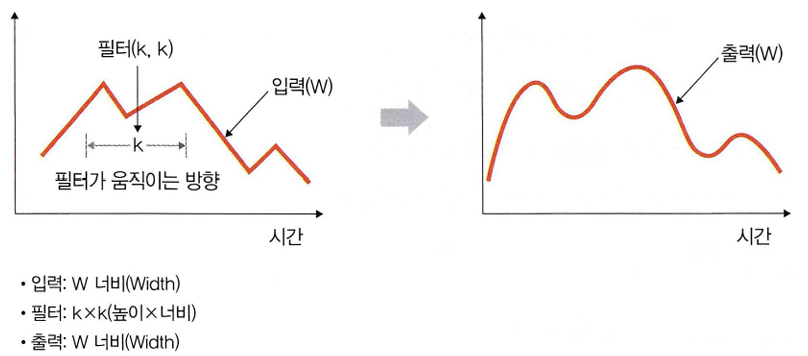

- 필터가 **시간 축을 따라 좌우로만** 이동함
- 입력 W(너비), 필터 k×k, 출력 W(너비) → 출력 형태는 **1D 배열**
- 예: 입력 [1, 1, 1, 1, 1], 필터 [0.25, 0.5, 0.25] → 출력 [1, 1, 1]
- **그래프 곡선을 완화**할 때 많이 사용함

**2D 합성곱**

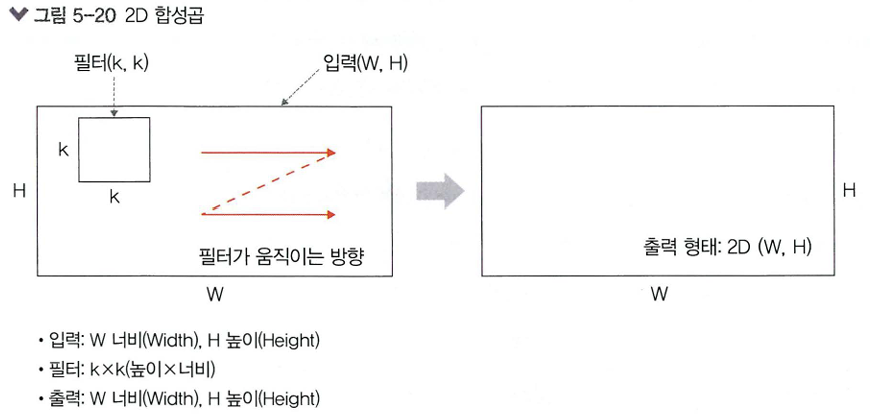

- 필터가 **두 방향**으로 움직임
- 입력 (W, H), 필터 (k, k) → 출력 (W, H) → 출력 형태는 **2D 행렬**

**3D 합성곱**

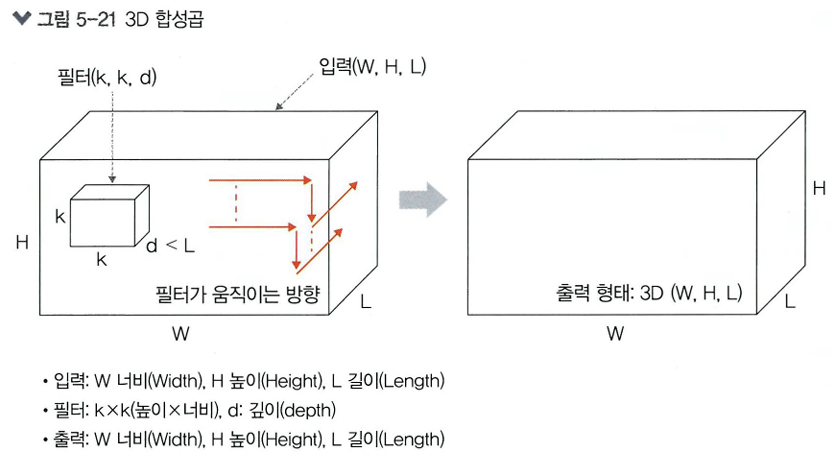

- 필터가 **세 방향**으로 움직임
- 입력 (W, H, L), 필터 (k, k, d) → 출력 (W, H, L) → 출력 형태는 **3D**
- 이때 **d < L을 유지**하는 것이 중요함 (필터 깊이가 입력 길이보다 작아야 깊이 방향으로도 움직일 수 있음)

**3D 입력을 갖는 2D 합성곱**

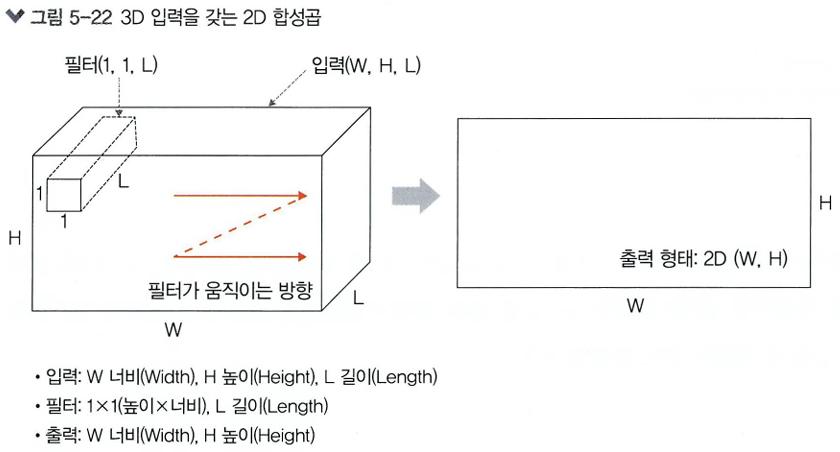

- 입력은 3D(예: 224×224×3, 112×112×32)인데 출력은 **2D 행렬**인 형태
- 필터의 길이(L)가 **입력 채널의 길이(L)와 같아야** 하기 때문에 이런 형태가 됨
- 입력 (W, H, L)에 필터 (k, k, L)를 적용하면 출력은 (W, H)
- 필터는 두 방향으로만 움직임
- 대표 사례: **LeNet-5, VGG** (6장에서 자세히 다룸)

**1×1 합성곱**

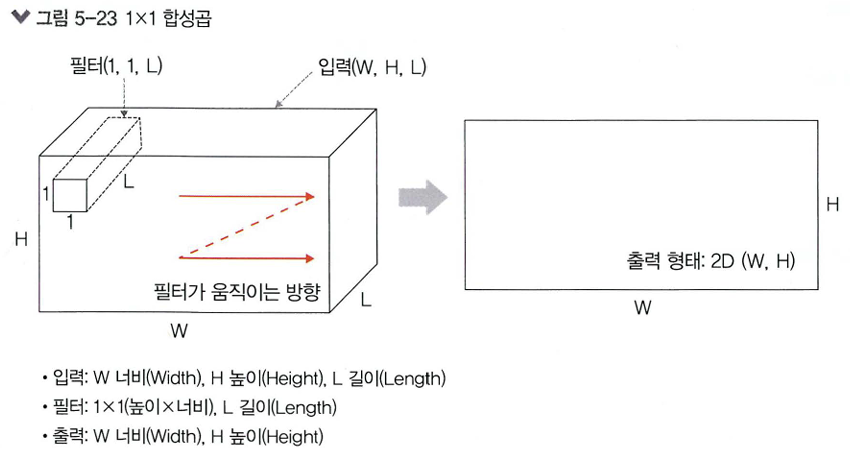

- 3D 형태로 입력됨
- 입력 (W, H, L)에 필터 (1, 1, L)를 적용하면 출력은 (W, H)
- **채널 수를 조정**해서 **연산량이 감소**하는 효과가 있음
- 대표 사례: **GoogLeNet** (6장에서 자세히 다룸)